In [10]:
# ==============================
# 1. IMPORTS
# ==============================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

# Visualization settings
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

# Reproducibility
RANDOM_STATE = 42

In [11]:
# ==============================
# 2. LOAD DATA
# ==============================

DATA_URL = (
    "https://raw.githubusercontent.com/"
    "IBM/telco-customer-churn-on-icp4d/"
    "master/data/Telco-Customer-Churn.csv"
)

df = pd.read_csv(DATA_URL)

print(f"Dataset shape: {df.shape}")
display(df.head())

Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [12]:
# ==============================
# 3. DATA UNDERSTANDING
# ==============================

print("Dataset Shape:", df.shape)

print("\nColumn Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nTarget Distribution:")
print(df["Churn"].value_counts())

print("\nNumerical Summary:")
display(df.describe())

Dataset Shape: (7043, 21)

Column Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 


,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


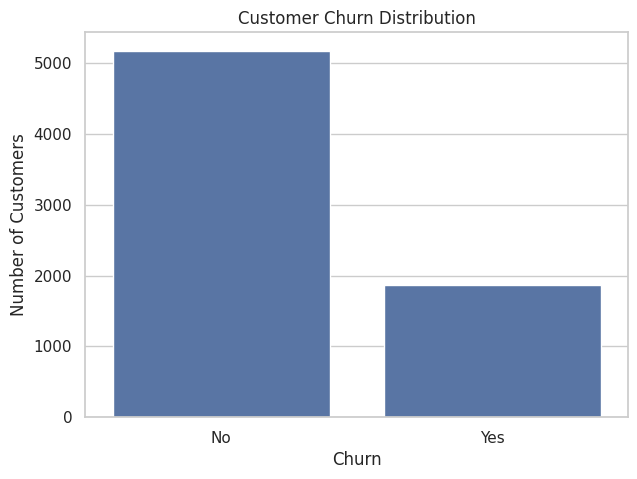

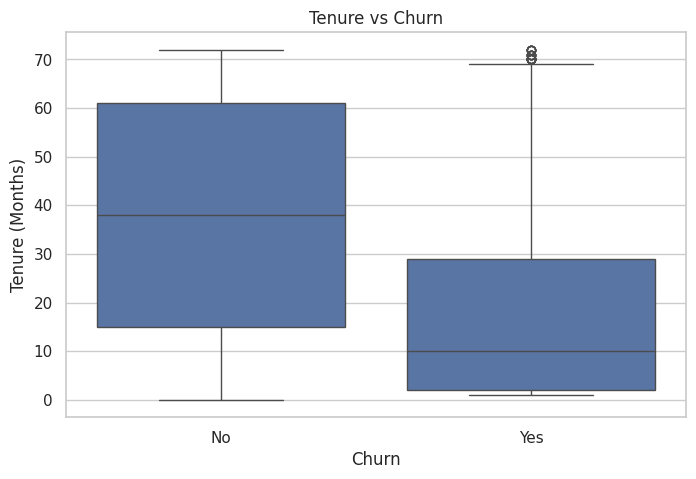

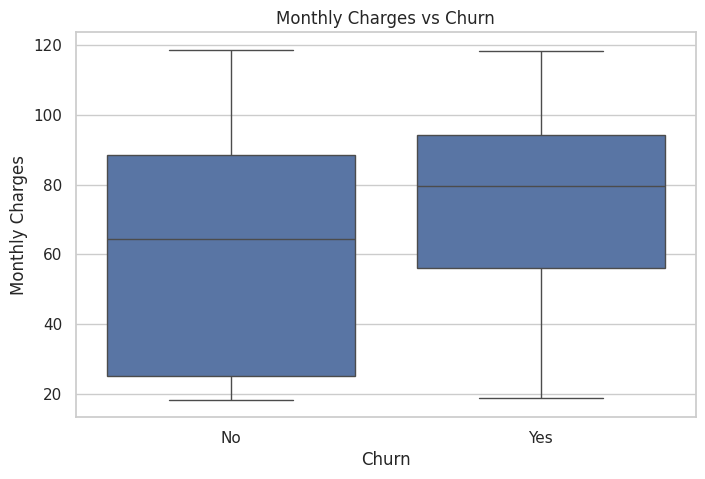

In [13]:
# ==============================
# 4. EXPLORATORY DATA ANALYSIS
# ==============================

# 4.1 Churn Distribution
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.show()


# 4.2 Tenure vs Churn
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="Churn", y="tenure")

plt.title("Tenure vs Churn")
plt.xlabel("Churn")
plt.ylabel("Tenure (Months)")
plt.show()


# 4.3 Monthly Charges vs Churn
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="Churn", y="MonthlyCharges")

plt.title("Monthly Charges vs Churn")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")
plt.show()

In [14]:
# ==============================
# 5. DATA CLEANING
# ==============================

# Convert TotalCharges to numeric
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

# Check missing values after conversion
print("Missing TotalCharges:", df["TotalCharges"].isnull().sum())

# Check rows with missing TotalCharges
display(df[df["TotalCharges"].isnull()].head())

# Remove customerID
df.drop(columns=["customerID"], inplace=True)

print("\nUpdated Dataset Shape:", df.shape)
print("\nData Types:")
print(df.dtypes)

Missing TotalCharges: 11


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,NaN,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,NaN,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,NaN,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,NaN,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,NaN,No



Updated Dataset Shape: (7043, 20)

Data Types:
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
Churn                object
dtype: object


In [15]:
# ==============================
# 6. FEATURE ENGINEERING
# ==============================

# Check rows with missing TotalCharges
print("Rows with missing TotalCharges:")
display(df[df["TotalCharges"].isnull()][["tenure", "MonthlyCharges", "TotalCharges"]])

# Separate features and target
X = df.drop(columns=["Churn"])
y = df["Churn"].map({"No": 0, "Yes": 1})

print("\nFeatures shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget values:")
print(y.value_counts())

Rows with missing TotalCharges:


,tenure,MonthlyCharges,TotalCharges
488,0,52.55,NaN
753,0,20.25,NaN
936,0,80.85,NaN
1082,0,25.75,NaN
1340,0,56.05,NaN
3331,0,19.85,NaN
3826,0,25.35,NaN
4380,0,20.00,NaN
5218,0,19.70,NaN
6670,0,73.35,NaN



Features shape: (7043, 19)
Target shape: (7043,)

Target values:
Churn
0    5174
1    1869
Name: count, dtype: int64


In [16]:
# ==============================
# 7. TRAIN / TEST SPLIT
# ==============================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (5634, 19)
X_test: (1409, 19)
y_train: (5634,)
y_test: (1409,)


In [17]:
# ==============================
# 8. PREPROCESSING PIPELINE
# ==============================

# Identify numerical and categorical columns
numerical_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical features:", numerical_features)
print("Categorical features:", categorical_features)

# Numerical preprocessing
numerical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing pipelines
preprocessor = ColumnTransformer(transformers=[
    ("num", numerical_pipeline, numerical_features),
    ("cat", categorical_pipeline, categorical_features)
])

# Fit on training data only
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("\nProcessed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

Numerical features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Processed training shape: (5634, 45)
Processed testing shape: (1409, 45)


In [18]:
# ==============================
# 9. MODEL TRAINING
# ==============================

# Train Logistic Regression
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=RANDOM_STATE
)

logistic_model.fit(X_train_processed, y_train)

# Make predictions
y_pred_logistic = logistic_model.predict(X_test_processed)

# Predicted probabilities for ROC-AUC
y_prob_logistic = logistic_model.predict_proba(
    X_test_processed
)[:, 1]

print("Logistic Regression training completed.")
print("Predictions generated:", len(y_pred_logistic))

Logistic Regression training completed.
Predictions generated: 1409


Logistic Regression Evaluation
-----------------------------------
Accuracy:  0.8055
Precision: 0.6572
Recall:    0.5588
F1-Score:  0.6040
ROC-AUC:   0.8419

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.85      0.89      0.87      1035
       Churn       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



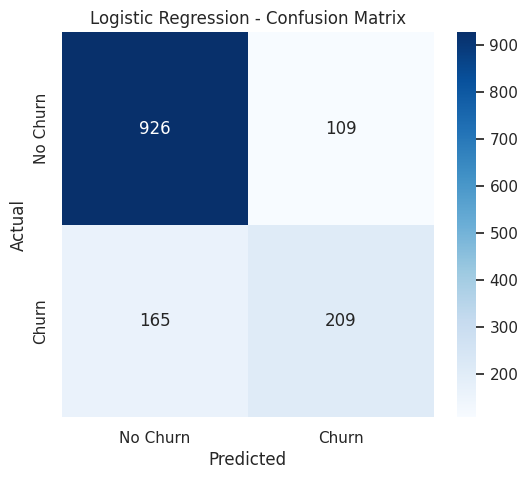

In [19]:
# ==============================
# 10. MODEL EVALUATION
# ==============================

print("Logistic Regression Evaluation")
print("-" * 35)

print(f"Accuracy:  {accuracy_score(y_test, y_pred_logistic):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_logistic):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_logistic):.4f}")
print(f"F1-Score:  {f1_score(y_test, y_pred_logistic):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, y_prob_logistic):.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_logistic,
    target_names=["No Churn", "Churn"]
))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred_logistic)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)

plt.title("Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [20]:
# ==============================
# 11. DECISION TREE MODEL
# ==============================

tree_model = DecisionTreeClassifier(
    max_depth=6,
    min_samples_split=10,
    min_samples_leaf=5,
    random_state=RANDOM_STATE
)

tree_model.fit(X_train_processed, y_train)

# Predictions
y_pred_tree = tree_model.predict(X_test_processed)

y_prob_tree = tree_model.predict_proba(
    X_test_processed
)[:, 1]

print("Decision Tree training completed.")
print("Predictions generated:", len(y_pred_tree))

Decision Tree training completed.
Predictions generated: 1409


In [21]:
# ==============================
# 12. DECISION TREE EVALUATION
# ==============================

print("Decision Tree Evaluation")
print("-" * 35)

print(f"Accuracy:  {accuracy_score(y_test, y_pred_tree):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_tree):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_tree):.4f}")
print(f"F1-Score:  {f1_score(y_test, y_pred_tree):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, y_prob_tree):.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_tree,
    target_names=["No Churn", "Churn"]
))

Decision Tree Evaluation
-----------------------------------
Accuracy:  0.7928
Precision: 0.6385
Recall:    0.5053
F1-Score:  0.5642
ROC-AUC:   0.8359

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.83      0.90      0.86      1035
       Churn       0.64      0.51      0.56       374

    accuracy                           0.79      1409
   macro avg       0.74      0.70      0.71      1409
weighted avg       0.78      0.79      0.78      1409



In [22]:
# ==============================
# 13. RANDOM FOREST MODEL
# ==============================

rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=12,
    min_samples_split=10,
    min_samples_leaf=4,
    class_weight="balanced",
    random_state=RANDOM_STATE,
    n_jobs=-1
)

rf_model.fit(X_train_processed, y_train)

# Predictions
y_pred_rf = rf_model.predict(X_test_processed)

y_prob_rf = rf_model.predict_proba(
    X_test_processed
)[:, 1]

print("Random Forest training completed.")
print("Predictions generated:", len(y_pred_rf))

Random Forest training completed.
Predictions generated: 1409


In [23]:
# ==============================
# 14. RANDOM FOREST EVALUATION
# ==============================

print("Random Forest Evaluation")
print("-" * 35)

print(f"Accuracy:  {accuracy_score(y_test, y_pred_rf):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_rf):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_rf):.4f}")
print(f"F1-Score:  {f1_score(y_test, y_pred_rf):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, y_prob_rf):.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_rf,
    target_names=["No Churn", "Churn"]
))

Random Forest Evaluation
-----------------------------------
Accuracy:  0.7679
Precision: 0.5475
Recall:    0.7246
F1-Score:  0.6237
ROC-AUC:   0.8397

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.89      0.78      0.83      1035
       Churn       0.55      0.72      0.62       374

    accuracy                           0.77      1409
   macro avg       0.72      0.75      0.73      1409
weighted avg       0.80      0.77      0.78      1409



In [24]:
# ==============================
# 15. MODEL COMPARISON
# ==============================

models = {
    "Logistic Regression": (y_pred_logistic, y_prob_logistic),
    "Decision Tree": (y_pred_tree, y_prob_tree),
    "Random Forest": (y_pred_rf, y_prob_rf)
}

results = []

for model_name, (y_pred, y_prob) in models.items():
    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-Score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="F1-Score",
    ascending=False
).reset_index(drop=True)

display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Random Forest,0.7679,0.5475,0.7246,0.6237,0.8397
1,Logistic Regression,0.8055,0.6572,0.5588,0.6040,0.8419
2,Decision Tree,0.7928,0.6385,0.5053,0.5642,0.8359


In [25]:
# ==============================
# 16. THRESHOLD TUNING
# ==============================

from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.base import clone

# Use only training data to choose the threshold
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

# Out-of-fold probabilities on training data
rf_cv_model = clone(rf_model)

y_train_prob_cv = cross_val_predict(
    rf_cv_model,
    X_train_processed,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

# Compare thresholds using F1-score
thresholds = np.arange(0.20, 0.61, 0.02)

threshold_results = []

for threshold in thresholds:
    y_train_pred_cv = (y_train_prob_cv >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_train, y_train_pred_cv, zero_division=0
        ),
        "Recall": recall_score(
            y_train, y_train_pred_cv, zero_division=0
        ),
        "F1-Score": f1_score(
            y_train, y_train_pred_cv, zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)

display(
    threshold_df.sort_values(
        "F1-Score", ascending=False
    ).head(10).round(4)
)

best_threshold = float(
    threshold_df.loc[
        threshold_df["F1-Score"].idxmax(),
        "Threshold"
    ]
)

print("Best threshold:", best_threshold)

,Threshold,Precision,Recall,F1-Score
10,0.40,0.5165,0.8167,0.6328
11,0.42,0.5228,0.7967,0.6313
12,0.44,0.5309,0.7766,0.6306
15,0.50,0.5592,0.7204,0.6296
16,0.52,0.5692,0.7043,0.6296
14,0.48,0.5483,0.7365,0.6286
18,0.56,0.5955,0.6656,0.6286
9,0.38,0.5038,0.8334,0.6280
17,0.54,0.5815,0.6823,0.6279
13,0.46,0.5356,0.7538,0.6263


Best threshold: 0.3999999999999999


In [26]:
# ==============================
# 17. EVALUATE TUNED THRESHOLD
# ==============================

best_threshold = 0.40

# Apply the new threshold to test probabilities
y_pred_rf_tuned = (
    y_prob_rf >= best_threshold
).astype(int)

print("Random Forest - Tuned Threshold")
print("-" * 40)

print(f"Threshold: {best_threshold:.2f}")
print(f"Accuracy:  {accuracy_score(y_test, y_pred_rf_tuned):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_rf_tuned):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_rf_tuned):.4f}")
print(f"F1-Score:  {f1_score(y_test, y_pred_rf_tuned):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, y_prob_rf):.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_rf_tuned,
    target_names=["No Churn", "Churn"]
))

Random Forest - Tuned Threshold
----------------------------------------
Threshold: 0.40
Accuracy:  0.7417
Precision: 0.5083
Recall:    0.8155
F1-Score:  0.6263
ROC-AUC:   0.8397

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.91      0.71      0.80      1035
       Churn       0.51      0.82      0.63       374

    accuracy                           0.74      1409
   macro avg       0.71      0.77      0.71      1409
weighted avg       0.81      0.74      0.76      1409



In [27]:
# ==============================
# 18. FINAL PIPELINE & SAVE
# ==============================

import joblib

# Combine preprocessing and model
final_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", rf_model)
])

# Train the complete pipeline on training data
final_pipeline.fit(X_train, y_train)

# Save model and threshold together
model_artifact = {
    "pipeline": final_pipeline,
    "threshold": 0.40,
    "target_mapping": {"No": 0, "Yes": 1}
}

joblib.dump(
    model_artifact,
    "customer_churn_model.joblib"
)

print("Final pipeline trained and saved successfully.")
print("File: customer_churn_model.joblib")

Final pipeline trained and saved successfully.
File: customer_churn_model.joblib


In [28]:
# ==============================
# 19. LOAD & TEST SAVED MODEL
# ==============================

import joblib

loaded_artifact = joblib.load("customer_churn_model.joblib")

loaded_pipeline = loaded_artifact["pipeline"]
threshold = loaded_artifact["threshold"]

# Predict probabilities for test data
test_probabilities = loaded_pipeline.predict_proba(X_test)[:, 1]

# Apply saved threshold
test_predictions = (test_probabilities >= threshold).astype(int)

print("Model loaded successfully.")
print("Threshold:", threshold)
print("Predictions generated:", len(test_predictions))
print("\nSample predictions:")
print(test_predictions[:10])

Model loaded successfully.
Threshold: 0.4
Predictions generated: 1409

Sample predictions:
[0 1 0 1 0 1 1 0 0 1]


In [29]:
# ==============================
# 20. PREDICTION FUNCTION
# ==============================

def predict_customer_churn(customer_data, artifact):
    """
    Predict whether a customer is likely to churn.

    customer_data: pandas DataFrame containing one customer's features.
    artifact: saved model artifact dictionary.
    """

    pipeline = artifact["pipeline"]
    threshold = artifact["threshold"]

    probability = pipeline.predict_proba(customer_data)[0, 1]
    prediction = int(probability >= threshold)

    return {
        "prediction": "Churn" if prediction == 1 else "No Churn",
        "churn_probability": round(float(probability), 4),
        "threshold": threshold
    }


print("Prediction function created successfully.")

Prediction function created successfully.


In [30]:
# ==============================
# 21. TEST PREDICTION FUNCTION
# ==============================

sample_customer = X_test.iloc[[0]]

result = predict_customer_churn(
    sample_customer,
    loaded_artifact
)

print("Prediction:", result["prediction"])
print("Churn Probability:", f'{result["churn_probability"]:.2%}')
print("Decision Threshold:", result["threshold"])

print("Actual Result:", "Churn" if y_test.iloc[0] == 1 else "No Churn")

Prediction: No Churn
Churn Probability: 2.00%
Decision Threshold: 0.4
Actual Result: No Churn


In [31]:
# Create README file

readme_content = """# Customer Churn Prediction

"""

with open("README.md", "w", encoding="utf-8") as file:
    file.write(readme_content)

print("README.md created successfully.")

README.md created successfully.


In [32]:
# ==============================
# README - PROJECT OVERVIEW
# ==============================

readme_content = """# Customer Churn Prediction

## Project Overview

Customer Churn Prediction is a machine learning project that aims to
identify customers who are likely to stop using a company's services.

The project uses customer account information, service subscriptions,
contract details, and billing data to predict customer churn.

Three machine learning models were evaluated:
- Logistic Regression
- Decision Tree
- Random Forest

The models were compared using Accuracy, Precision, Recall, F1-Score,
and ROC-AUC.
"""

with open("README.md", "w", encoding="utf-8") as file:
    file.write(readme_content)

print("Project Overview added to README.md")

Project Overview added to README.md


In [33]:
# ==============================
# README - DATASET DESCRIPTION
# ==============================

with open("README.md", "a", encoding="utf-8") as file:
    file.write("""
## Dataset Description

The project uses the IBM Telco Customer Churn dataset.

- **Total records:** 7,043 customers
- **Original columns:** 21
- **Target variable:** `Churn`
- **Target classes:** `Yes` and `No`
- **Features:** Customer demographics, subscribed services,
  contract details, and billing information.

### Target Distribution

- **No Churn:** 5,174 customers
- **Churn:** 1,869 customers

The `customerID` column was removed because it is an identifier
rather than a useful predictive feature.
The `TotalCharges` column was converted to a numeric data type.
""")

print("Dataset Description added to README.md")

Dataset Description added to README.md


In [34]:
# ==============================
# README - TOOLS & TECHNOLOGIES
# ==============================

with open("README.md", "a", encoding="utf-8") as file:
    file.write("""
## Tools & Technologies

- **Programming Language:** Python
- **Data Analysis:** Pandas, NumPy
- **Data Visualization:** Matplotlib, Seaborn
- **Machine Learning:** Scikit-learn
- **Environment:** Google Colab
- **Model Persistence:** Joblib
- **Version Control:** Git and GitHub
""")

print("Tools & Technologies added to README.md")

Tools & Technologies added to README.md


In [35]:
# ==============================
# README - PROJECT WORKFLOW
# ==============================

with open("README.md", "a", encoding="utf-8") as file:
    file.write("""
## Project Workflow

1. **Data Loading:** Loaded the IBM Telco Customer Churn dataset.
2. **Data Cleaning:** Removed `customerID` and converted `TotalCharges`
   to a numeric format.
3. **Exploratory Data Analysis:** Examined churn distribution and
   customer features.
4. **Data Preprocessing:** Handled missing values, scaled numerical
   features, and encoded categorical features.
5. **Train-Test Split:** Split the data into training and testing sets
   using stratified sampling.
6. **Model Training:** Trained Logistic Regression, Decision Tree,
   and Random Forest models.
7. **Model Evaluation:** Compared models using Accuracy, Precision,
   Recall, F1-Score, and ROC-AUC.
8. **Threshold Tuning:** Selected a 0.40 probability threshold to
   improve churn detection.
9. **Model Pipeline:** Saved the preprocessing and trained model
   together using Joblib.
10. **Prediction Testing:** Loaded the saved artifact and tested
    predictions on customer records.
""")

print("Project Workflow added to README.md")

Project Workflow added to README.md


In [36]:
# ==============================
# README - MODEL PERFORMANCE
# ==============================

with open("README.md", "a", encoding="utf-8") as file:
    file.write("""
## Model Performance

Three machine learning models were evaluated on the test set.

| Model | Accuracy | Precision | Recall | F1-Score | ROC-AUC |
|---|---:|---:|---:|---:|---:|
| Logistic Regression | 80.55% | 65.72% | 55.88% | 60.40% | 84.19% |
| Decision Tree | 79.28% | 63.85% | 50.53% | 56.42% | 83.59% |
| Random Forest | 76.79% | 54.75% | 72.46% | 62.37% | 83.97% |

### Threshold Tuning

The Random Forest model was evaluated using a probability threshold
of `0.40` instead of the default `0.50`.

| Metric | Result |
|---|---:|
| Accuracy | 74.17% |
| Precision | 50.83% |
| Recall | 81.55% |
| F1-Score | 62.63% |
| ROC-AUC | 83.97% |

The lower threshold improved Recall, helping the model identify more
customers who were likely to churn, at the cost of lower Precision
and more false-positive predictions.

**Note:** The threshold was selected using cross-validation on the
training data. Final performance was measured on the held-out test set.
""")

print("Model Performance added to README.md")

Model Performance added to README.md


In [40]:
from pathlib import Path

section = [
    "",
    "## How to Use",
    "",
    "### Requirements",
    "",
    "- Python 3",
    "- Pandas",
    "- NumPy",
    "- Scikit-learn",
    "- Joblib",
    "",
    "### Load the Saved Model",
    "",
    "```python",
    "import joblib",
    "",
    'artifact = joblib.load("customer_churn_model.joblib")',
    'pipeline = artifact["pipeline"]',
    'threshold = artifact["threshold"]',
    "```",
    "",
    "### Make a Prediction",
    "",
    "Provide customer data in a Pandas DataFrame named `customer_data`.",
    "",
    "```python",
    "probability = pipeline.predict_proba(customer_data)[0, 1]",
    'prediction = "Churn" if probability >= threshold else "No Churn"',
    'print("Prediction:", prediction)',
    'print("Churn Probability:", round(probability * 100, 2), "%")',
    "```",
    "",
    "The pipeline automatically applies preprocessing before prediction.",
    ""
]

with open("README.md", "a", encoding="utf-8") as file:
    file.write("\n".join(section))

print("How to Use added to README.md")

How to Use added to README.md


In [41]:
section = [
    "",
    "## Limitations",
    "",
    "- The model was trained on a single Telco customer churn dataset.",
    "- The selected threshold increases Recall but also produces more false positives.",
    "- Model performance may vary on data from different companies.",
    "- Predictions indicate churn risk and should not be treated as certain outcomes.",
    "",
    "## Future Improvements",
    "",
    "- Perform more extensive hyperparameter tuning.",
    "- Explore additional classification models.",
    "- Improve feature engineering.",
    "- Evaluate the model on new, unseen datasets.",
    "- Develop an interactive application for customer churn predictions.",
    ""
]

with open("README.md", "a", encoding="utf-8") as file:
    file.write("\n".join(section))

print("Limitations & Future Improvements added to README.md")

Limitations & Future Improvements added to README.md


In [42]:
from pathlib import Path

readme_path = Path("README.md")
content = readme_path.read_text(encoding="utf-8")

print(content)
print("\n" + "=" * 40)
print("Total characters:", len(content))
print("File exists:", readme_path.exists())

# Customer Churn Prediction

## Project Overview

Customer Churn Prediction is a machine learning project that aims to
identify customers who are likely to stop using a company's services.

The project uses customer account information, service subscriptions,
contract details, and billing data to predict customer churn.

Three machine learning models were evaluated:
- Logistic Regression
- Decision Tree
- Random Forest

The models were compared using Accuracy, Precision, Recall, F1-Score,
and ROC-AUC.

## Dataset Description

The project uses the IBM Telco Customer Churn dataset.

- **Total records:** 7,043 customers
- **Original columns:** 21
- **Target variable:** `Churn`
- **Target classes:** `Yes` and `No`
- **Features:** Customer demographics, subscribed services,
  contract details, and billing information.

### Target Distribution

- **No Churn:** 5,174 customers
- **Churn:** 1,869 customers

The `customerID` column was removed because it is an identifier
rather than a useful pr

In [43]:
from google.colab import files

files.download("README.md")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [44]:
files.download("customer_churn_model.joblib")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [45]:
import os

print("Model size:", round(
    os.path.getsize("customer_churn_model.joblib") / (1024 * 1024), 2
), "MB")

Model size: 10.26 MB
